In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sea
import statsmodels.api as sm
import scipy.stats as stats
from scipy.stats import contingency
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

import warnings
warnings.filterwarnings("ignore")

### Datenaufbereitung

Lade den Datensatz über die verfügbaren Apps im Google Play Store (googleplaystore.csv).

Überprüfe die Datenqualität anhand der Merkmale *Type* und *Price*. Gibt es Apps, die im Merkmal *Type* eine Merkmalsausprägung *Free* haben, aber einen Preis ungleich Null? Ebenso soll überprüft werden, ob es Apps mit *Price = 0* gibt, deren *Type* von *Free* abweicht. Einträge, die diese Kriterien verletzen, sollen aus dem Datensatz entfernt werden.

Überprüfe abschließend, ob Duplikate in den Einträgen existieren, und entferne diese gegebenenfalls.

In [5]:
df = pd.read_csv("./data/googleplaystore.csv")

print("Vorher:", df.shape)

df['Price'] = df['Price'].replace('Everyone', np.nan)
df['Price'] = df['Price'].str.replace('$','', regex=True)
df['Price'] = pd.to_numeric(df['Price'], errors='coerce').fillna(0)


condition1 = (df['Type'] == 'Free') & (df['Price'] > 0)

condition2 = (df['Price'] == 0) & (df['Type'] != 'Free')

print("Fehlerhafte Einträge (Free & Price>0):", condition1.sum())
print("Fehlerhafte Einträge (Price=0 & Type!=Free):", condition2.sum())

df_clean = df[~(condition1 | condition2)].copy()

print("Nach Bereinigung:", df_clean.shape)

dups = df_clean.duplicated().sum()
print("Anzahl Duplikate:", dups)

df_clean = df_clean.drop_duplicates()
print("Endgültige Form:", df_clean.shape)

Vorher: (10841, 13)
Fehlerhafte Einträge (Free & Price>0): 0
Fehlerhafte Einträge (Price=0 & Type!=Free): 802
Nach Bereinigung: (10039, 13)
Anzahl Duplikate: 448
Endgültige Form: (9591, 13)


### Datenuntersuchung

Gib folgende Kennzahlen und Eigenschaften des Datensatzes an:  
- Wie viele Einträge existieren?  
- Auf welchen Skalen sind die unterschiedlichen Merkmale definiert?  
- Welchen Modus haben die Merkmale *Category*, *Content Rating* und *Genres*?  

Stelle zusätzlich folgende Grafiken dar:  
- für *Category*: absolute Häufigkeit  
- für *Content Rating*: relative Häufigkeit  
- für *Genres*: absolute Häufigkeit der Top 20, sortiert nach Anzahl  

Wie viele Merkmalsausprägungen existieren für *Genres*?

Anzahl der Einträge im bereinigten Datensatz: 9591

Skalenarten:
App             -> nominal
Category        -> nominal
Rating          -> metrisch (stetig)
Reviews         -> metrisch (diskret)
Size            -> metrisch (stetig, aber textbasiert kodiert, muss evtl. transformiert werden)
Installs        -> metrisch (diskret, aber als kategorial formatiert, da Text mit + und , )
Type            -> nominal
Price           -> metrisch (stetig)
Content Rating  -> ordinal (kategorial, da Altersklassen)
Genres          -> nominal
Last Updated    -> metrisch (Zeit)
Current Ver     -> nominal (eigentlich Versionsnummer)
Android Ver     -> ordinal (mindestens Version X)

Modus:
Category: FAMILY
Content Rating: Everyone
Genres: Tools


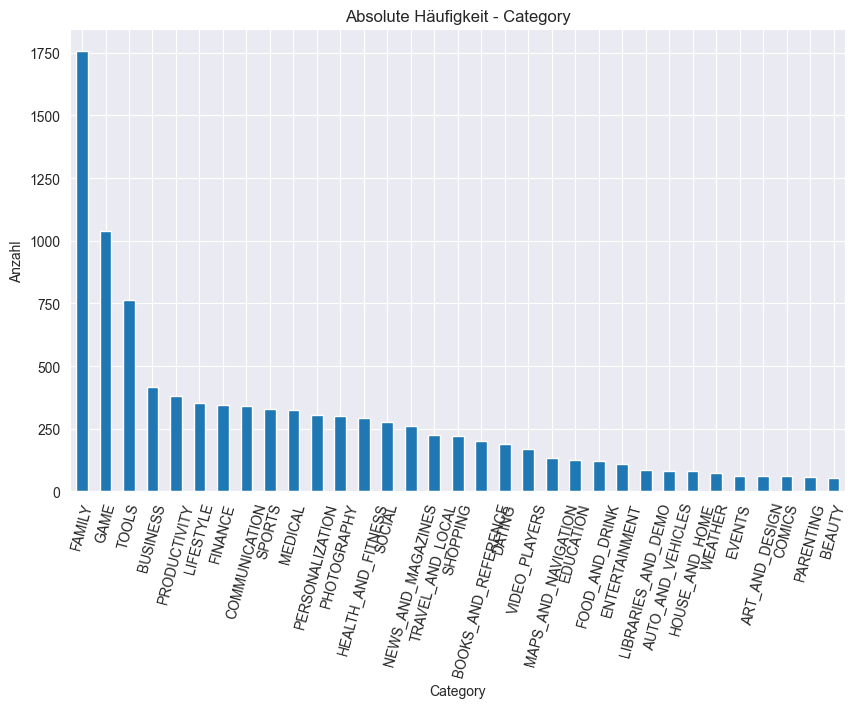

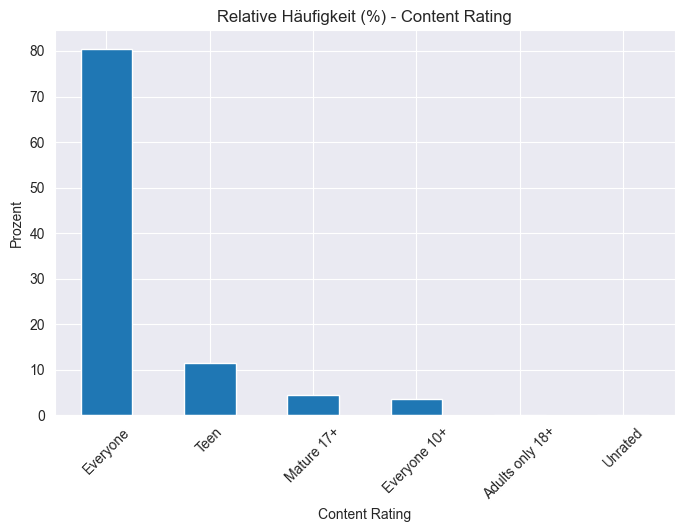

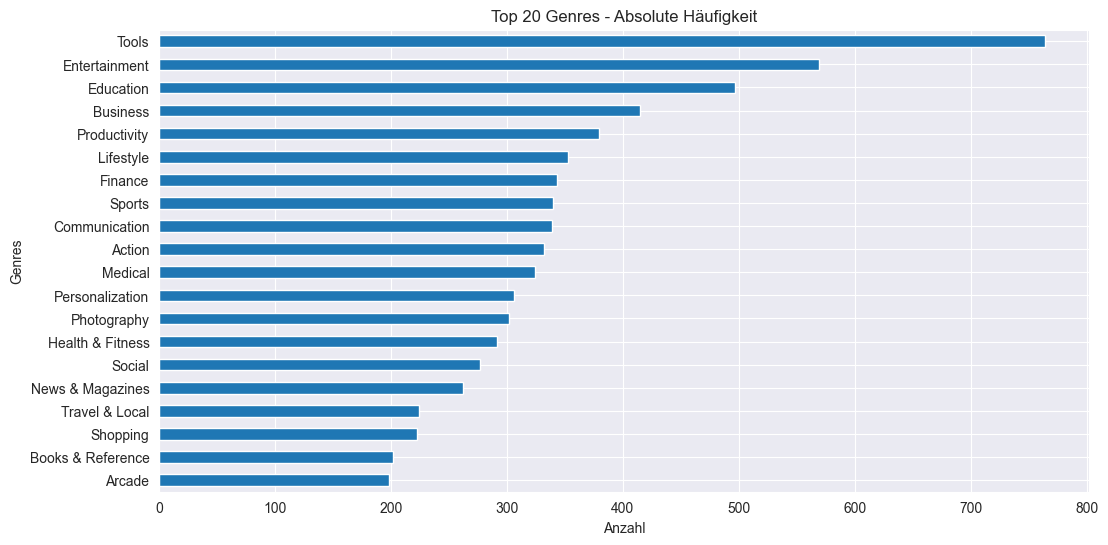


Anzahl verschiedener Genres: 115


In [6]:
print("Anzahl der Einträge im bereinigten Datensatz:", df_clean.shape[0])

skalen = {
    "App": "nominal",
    "Category": "nominal",
    "Rating": "metrisch (stetig)",
    "Reviews": "metrisch (diskret)",
    "Size": "metrisch (stetig, aber textbasiert kodiert, muss evtl. transformiert werden)",
    "Installs": "metrisch (diskret, aber als kategorial formatiert, da Text mit + und , )",
    "Type": "nominal",
    "Price": "metrisch (stetig)",
    "Content Rating": "ordinal (kategorial, da Altersklassen)",
    "Genres": "nominal",
    "Last Updated": "metrisch (Zeit)",
    "Current Ver": "nominal (eigentlich Versionsnummer)",
    "Android Ver": "ordinal (mindestens Version X)"
}

print("\nSkalenarten:")
for k,v in skalen.items():
    print(f"{k:15} -> {v}")

print("\nModus:")
print("Category:", df_clean['Category'].mode()[0])
print("Content Rating:", df_clean['Content Rating'].mode()[0])
print("Genres:", df_clean['Genres'].mode()[0])


plt.figure(figsize=(10,6))
df_clean['Category'].value_counts().plot(kind="bar")
plt.title("Absolute Häufigkeit - Category")
plt.ylabel("Anzahl")
plt.xticks(rotation=75)
plt.show()

plt.figure(figsize=(8,5))
(df_clean['Content Rating'].value_counts(normalize=True)*100).plot(kind="bar")
plt.title("Relative Häufigkeit (%) - Content Rating")
plt.ylabel("Prozent")
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(12,6))
df_clean['Genres'].value_counts().head(20).sort_values(ascending=True).plot(kind="barh")
plt.title("Top 20 Genres - Absolute Häufigkeit")
plt.xlabel("Anzahl")
plt.show()

anzahl_genres = df_clean['Genres'].nunique()
print("\nAnzahl verschiedener Genres:", anzahl_genres)


### Zusammenhang Qualitative Merkmale

Erstelle die Kreuztabelle für die Merkmale *Content Rating* und *Type*. Berechne damit die folgenden bedingten Häufigkeiten:

- P(Paid | Everyone)  
- P(Mature | Free)  
- Die Wahrscheinlichkeit, dass eine App mit Content Rating *Teen* kostenlos ist.  

Bewerte anschließend die statistische Abhängigkeit der beiden Merkmale basierend auf dem korrigierten Kontingenzkoeffizienten.  


In [9]:
ct = pd.crosstab(df_clean['Content Rating'], df_clean['Type'])
print(ct)

cols = ct.columns.tolist()
rows = ct.index.tolist()

if "Paid" in cols and "Everyone" in rows:
    p_paid_given_everyone = ct.loc["Everyone", "Paid"] / ct.loc["Everyone"].sum()
else:
    p_paid_given_everyone = np.nan

if "Free" in cols and "Mature 17+" in rows:
    p_mature_given_free = ct.loc["Mature 17+", "Free"] / ct["Free"].sum()
else:
    p_mature_given_free = np.nan

if "Free" in cols and "Teen" in rows:
    p_free_given_teen = ct.loc["Teen", "Free"] / ct.loc["Teen"].sum()
else:
    p_free_given_teen = np.nan

print("\nBedingte Wahrscheinlichkeiten:")
print("P(Paid | Everyone) =", p_paid_given_everyone)
print("P(Mature | Free)   =", p_mature_given_free)
print("P(Free | Teen)     =", p_free_given_teen)

chi2, p, dof, expected = stats.chi2_contingency(ct)
n = ct.to_numpy().sum()
kontingenz = np.sqrt(chi2 / (chi2 + n))
korr_kontingenz = kontingenz / np.sqrt((min(ct.shape)-1) / min(ct.shape))

print("\nChi²-Test:")
print("Chi² =", round(chi2,2), "  p-Wert =", round(p,4))
print("Kontingenzkoeffizient =", round(kontingenz,4))
print("Korrigierter Kontingenzkoeffizient =", round(korr_kontingenz,4))


Type             Free
Content Rating       
Adults only 18+     3
Everyone         7720
Everyone 10+      344
Mature 17+        428
Teen             1094
Unrated             2

Bedingte Wahrscheinlichkeiten:
P(Paid | Everyone) = nan
P(Mature | Free)   = 0.04462516942967365
P(Free | Teen)     = 1.0

Chi²-Test:
Chi² = 0.0   p-Wert = 1.0
Kontingenzkoeffizient = 0.0
Korrigierter Kontingenzkoeffizient = nan


### Quantitative Merkmale

Lade den Datensatz *Advertising.csv* ein.

Der Datensatz hat 4 Merkmale und 200 Beobachtungen. Die Merkmale sind:
- *TV* - Werbebudget in Geldeinheiten [GE] für Spots im TV
- *radio* - Werbebudget in GE für Ansagen im Radio
- *newspaper* - Werbebudget in GE für Announcen in Zeitungen
- *sales* - Anzahl verkaufter Produkte [in Tsd.].

Fragestellungen:  
- Stelle für das Merkmal *TV* einen kumulativen Häufigkeitsplot dar. Welches minimale Budget haben die 30% Kampagnen mit dem höchsten TV-Budget?  
- Stelle für das Merkmal *newspaper* einen Boxplot dar. Wie viele Ausreißer existieren?

Gib zusätzlich für alle Merkmale jeweils den Median, den Interquartilsabstand, den arithmetischen Mittelwert und die Standardabweichung an.  

Form des Datensatzes: (200, 5)
   Unnamed: 0     TV  radio  newspaper  sales
0           0  230.1   37.8       69.2   22.1
1           1   44.5   39.3       45.1   10.4
2           2   17.2   45.9       69.3    9.3
3           3  151.5   41.3       58.5   18.5
4           4  180.8   10.8       58.4   12.9


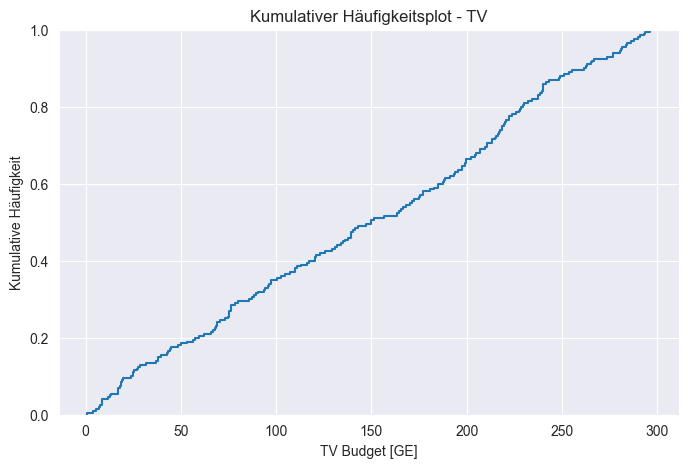

Minimales TV-Budget der 30% teuersten Kampagnen: 210.73 GE


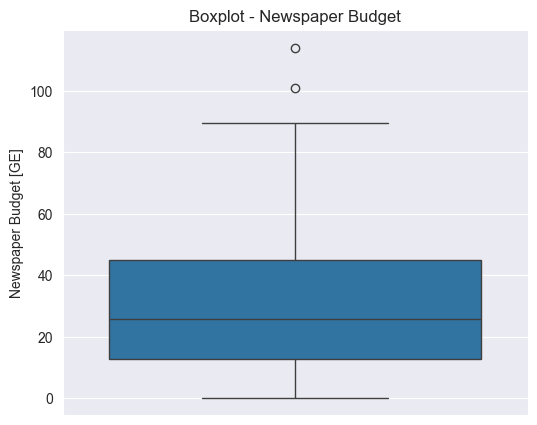

Anzahl Ausreißer im Newspaper-Budget: 2

Kennzahlen aller Merkmale:
            Median      IQR  Mittelwert  Standardabweichung
Unnamed: 0   99.50   99.500     99.5000           57.879185
TV          149.75  144.450    147.0425           85.854236
radio        22.90   26.550     23.2640           14.846809
newspaper    25.75   32.350     30.5540           21.778621
sales        12.90    7.025     14.0225            5.217457


In [10]:
df = pd.read_csv("./data/Advertising.csv")

print("Form des Datensatzes:", df.shape)
print(df.head())

plt.figure(figsize=(8,5))
sea.ecdfplot(df['TV'])
plt.title("Kumulativer Häufigkeitsplot - TV")
plt.xlabel("TV Budget [GE]")
plt.ylabel("Kumulative Häufigkeit")
plt.show()

grenze_30 = df['TV'].quantile(0.70)
print("Minimales TV-Budget der 30% teuersten Kampagnen:", round(grenze_30,2), "GE")

plt.figure(figsize=(6,5))
sea.boxplot(y=df['newspaper'])
plt.title("Boxplot - Newspaper Budget")
plt.ylabel("Newspaper Budget [GE]")
plt.show()

Q1 = df['newspaper'].quantile(0.25)
Q3 = df['newspaper'].quantile(0.75)
IQR = Q3 - Q1
untergrenze = Q1 - 1.5*IQR
obergrenze = Q3 + 1.5*IQR

ausreisser = ((df['newspaper'] < untergrenze) | (df['newspaper'] > obergrenze)).sum()
print("Anzahl Ausreißer im Newspaper-Budget:", ausreisser)

kennzahlen = pd.DataFrame({
    'Median': df.median(),
    'IQR': df.quantile(0.75) - df.quantile(0.25),
    'Mittelwert': df.mean(),
    'Standardabweichung': df.std()
})

print("\nKennzahlen aller Merkmale:")
print(kennzahlen)


### Zusammenhänge quantitativer Merkmale

Stelle einen pairplot für den Datensatz dar und bestimme die Korrelationsmatrix.

Berechne die Lineare Regression für *sales* basierend auf *TV* und beantworte folgende Fragen:
- Wie lautet das Modell der Linearen Regression?
- Sind die Koeffizienten signifikant?
- Welche Aussagen über die Residuen lassen ableiten?
- Welche Aussage lässt sich aus dem Bestimmtsmaß ableiten?  
- Würdest du das Modell in der Praxis benutzen?

Stelle zusätzlich Grafiken dar, um das Ergebnis und die Qualität der Linearen Regression zu visualisieren.


Bestimme danach die multiple lineare Regression für *sales* bei Benutzung der aller Merkmale.

Beantworte folgende Fragen:

- Ist die multiple lineare Regression *besser* als die einfache lineare Regression?
- Haben alle 3 Merkmale einen Einfluss auf das Ergebnis?

Stelle auch für diesen Fall Grafiken dar, um das Ergebnis und die Qualität zu visualisieren. 

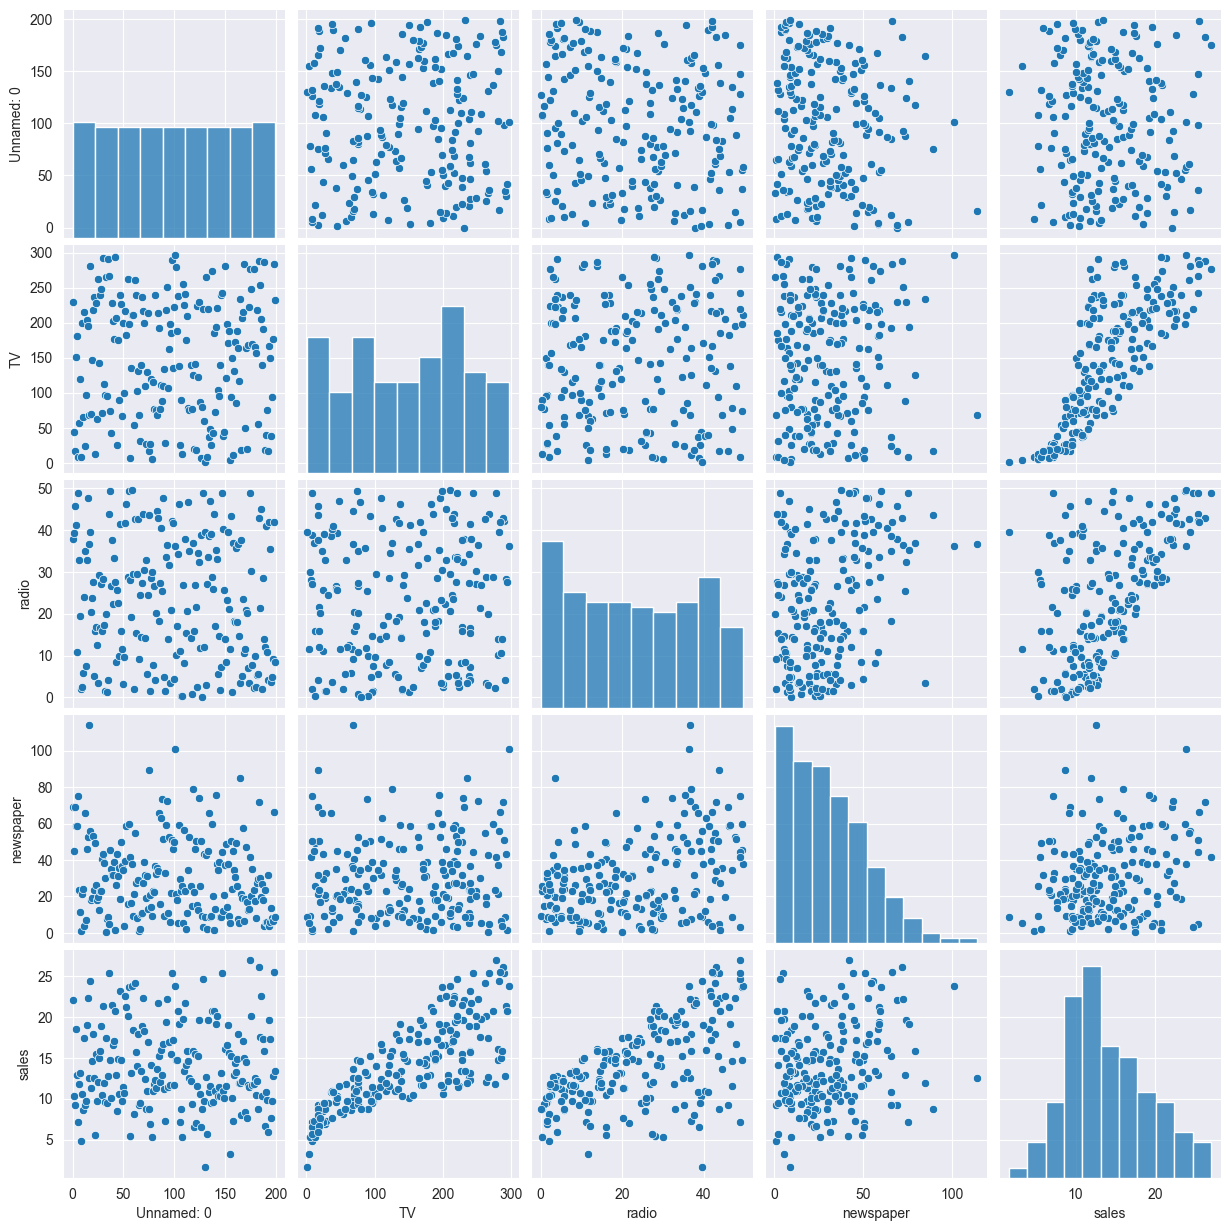

Korrelationsmatrix:
            Unnamed: 0        TV     radio  newspaper     sales
Unnamed: 0    1.000000  0.017715 -0.110680  -0.154944 -0.051616
TV            0.017715  1.000000  0.054809   0.056648  0.782224
radio        -0.110680  0.054809  1.000000   0.354104  0.576223
newspaper    -0.154944  0.056648  0.354104   1.000000  0.228299
sales        -0.051616  0.782224  0.576223   0.228299  1.000000
                            OLS Regression Results                            
Dep. Variable:                  sales   R-squared:                       0.612
Model:                            OLS   Adj. R-squared:                  0.610
Method:                 Least Squares   F-statistic:                     312.1
Date:                Wed, 22 Oct 2025   Prob (F-statistic):           1.47e-42
Time:                        18:33:47   Log-Likelihood:                -519.05
No. Observations:                 200   AIC:                             1042.
Df Residuals:                     198   BIC

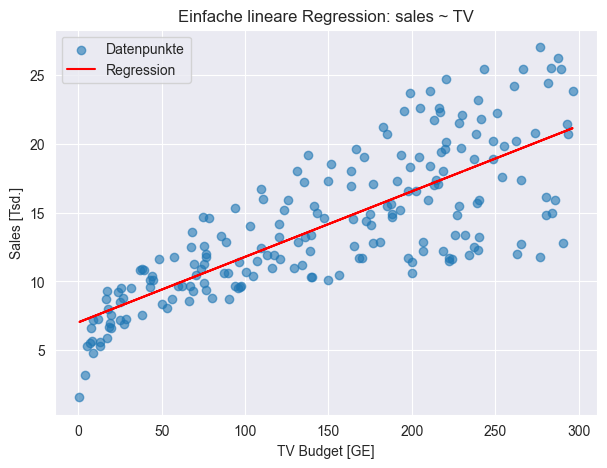

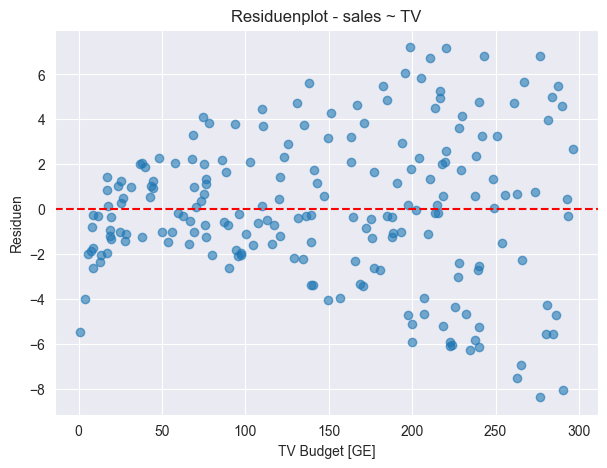

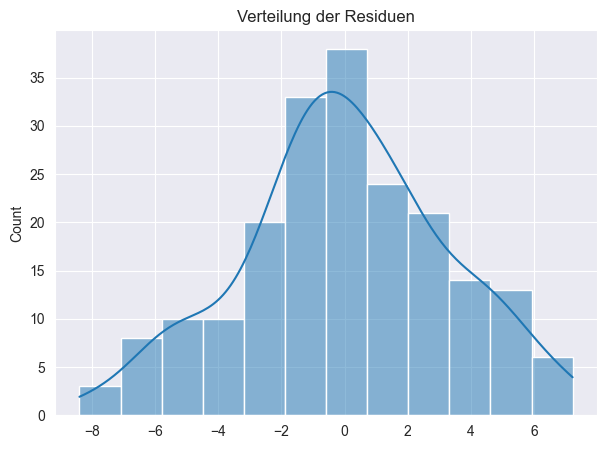

                            OLS Regression Results                            
Dep. Variable:                  sales   R-squared:                       0.897
Model:                            OLS   Adj. R-squared:                  0.896
Method:                 Least Squares   F-statistic:                     570.3
Date:                Wed, 22 Oct 2025   Prob (F-statistic):           1.58e-96
Time:                        18:33:47   Log-Likelihood:                -386.18
No. Observations:                 200   AIC:                             780.4
Df Residuals:                     196   BIC:                             793.6
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.9389      0.312      9.422      0.0

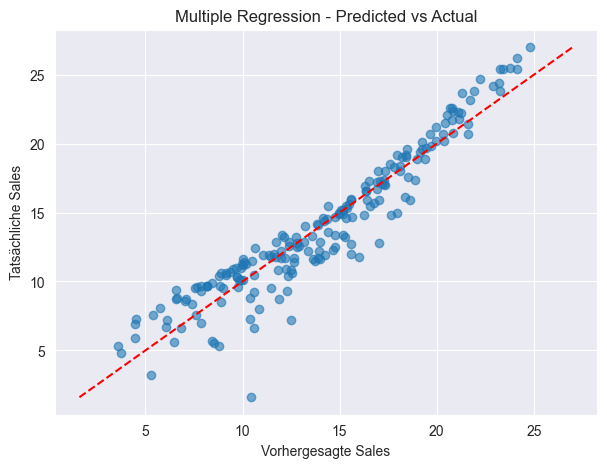

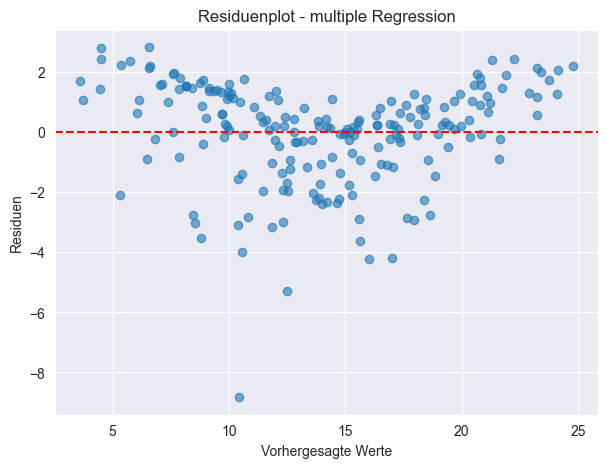

In [11]:
df = pd.read_csv("./data/Advertising.csv")

sea.pairplot(df)
plt.show()

print("Korrelationsmatrix:")
print(df.corr())

X = sm.add_constant(df['TV'])
y = df['sales']

model_simple = sm.OLS(y, X).fit()
print(model_simple.summary())

intercept = model_simple.params['const']
slope = model_simple.params['TV']
print(f"\nLineares Modell: sales = {intercept:.3f} + {slope:.3f} * TV")

resid = model_simple.resid

plt.figure(figsize=(7,5))
plt.scatter(df['TV'], df['sales'], alpha=0.6, label="Datenpunkte")
plt.plot(df['TV'], model_simple.predict(X), color="red", label="Regression")
plt.xlabel("TV Budget [GE]")
plt.ylabel("Sales [Tsd.]")
plt.title("Einfache lineare Regression: sales ~ TV")
plt.legend()
plt.show()

plt.figure(figsize=(7,5))
plt.scatter(df['TV'], resid, alpha=0.6)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("TV Budget [GE]")
plt.ylabel("Residuen")
plt.title("Residuenplot - sales ~ TV")
plt.show()

plt.figure(figsize=(7,5))
sea.histplot(resid, kde=True)
plt.title("Verteilung der Residuen")
plt.show()

X_multi = sm.add_constant(df[['TV','radio','newspaper']])
y = df['sales']

model_multi = sm.OLS(y, X_multi).fit()
print(model_multi.summary())

plt.figure(figsize=(7,5))
plt.scatter(model_multi.fittedvalues, y, alpha=0.6)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color="red", linestyle="--")
plt.xlabel("Vorhergesagte Sales")
plt.ylabel("Tatsächliche Sales")
plt.title("Multiple Regression - Predicted vs Actual")
plt.show()

plt.figure(figsize=(7,5))
plt.scatter(model_multi.fittedvalues, model_multi.resid, alpha=0.6)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Vorhergesagte Werte")
plt.ylabel("Residuen")
plt.title("Residuenplot - multiple Regression")
plt.show()
